# AVIPE signal chain: the math

Each step below is one block of the chain, written as the math it does:

microphone → sum of 3 → DC removal → 512-sample frames → FFT → frame to MCU → Hamming window + magnitude

Change anything in the **Inputs** cell and run all cells to see what it does at each step.

## 0. Inputs

In [ ]:
# ======================= INPUTS =======================
# ---- rates ----
MIC_RATE   = 46_875         # mic samples per second, Hz

# ---- microphone ----
MIC_BITS   = 18             # bits per mic sample, two's complement

# ---- input source ----
# 'tone'    : DC_OFFSET + one sine at TONE_HZ + noise
# 'chirp'   : DC_OFFSET + a sweep from CHIRP_F0 to CHIRP_F1 + noise
# 'speech'  : DC_OFFSET + a vowel-like buzz at PITCH_HZ shaped by FORMANTS_HZ + noise
# 'click'   : 0 except CLICK_LEVEL for the 3 mic samples of output sample CLICK_AT
# 'silence' : all 0
# 'wav'     : the file WAV_PATH, resampled to MIC_RATE
# 'mic'     : your microphone (records one snapshot, then runs the live plot at the end)
SOURCE      = 'mic'

# ---- synthetic signals, in mic LSBs ----
TONE_HZ     = 150 * 15625 / 512              # 4577.6 Hz: lands exactly on a bin for FRAME_N = 256, 512, 1024, 2048
TONE_AMP    = 8000
DC_OFFSET   = -3000
NOISE_LSB   = 500                            # rms white noise, in mic LSBs
CHIRP_F0, CHIRP_F1, CHIRP_AMP = 100, 7800, 6000
PITCH_HZ, FORMANTS_HZ, SPEECH_AMP = 140, [700, 1220, 2600], 6000
CLICK_AT, CLICK_LEVEL = 500, 5000
SEED        = 1

# ---- real audio ----
WAV_PATH     = 'input.wav'  # for SOURCE = 'wav'
MIC_DEVICE   = None         # for SOURCE = 'mic': None = system default, or a device number / name
MIC_GAIN     = 1.0          # real audio: 1.0 maps digital full scale to the mic's full scale
LIVE_SECONDS = 10           # length of the live plot when SOURCE = 'mic'

# ---- sum of 3 ----
SUM_N      = 1              # mic samples added per output sample

# ---- DC removal ----
AVERAGE_SHIFT = 10          # running average weight a = 2**-AVERAGE_SHIFT
OUT_BITS      = 16          # output sample width; values past it are clipped

# ---- frames ----
FRAME_N      = 512          # samples per frame = FFT points; change this freely
FRAMES_PER_S = 50           # frames sent per second (the hop between frames follows from it)

# ---- FFT ----
FFT_OUT_BITS = 16           # bits for re and im of each bin; the whole frame shares one power-of-2 scale

# ---- output ----
N_FRAMES       = 12         # frames to compute
FRAME_TO_PLOT  = 12         # which frame to send through the FFT (1 = first)
# ======================================================

In [212]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

FS        = MIC_RATE / SUM_N                       # output sample rate
SUM_BITS  = MIC_BITS + int(np.ceil(np.log2(SUM_N)))
A         = 2.0 ** -AVERAGE_SHIFT                  # running average weight
BIN_HZ    = FS / FRAME_N
HOP       = min(FRAME_N, round(FS / FRAMES_PER_S))  # new samples between frames
SEND_BINS = FRAME_N // 2                           # bins sent to the MCU
FIRST_END = -(-FRAME_N // HOP) * HOP               # samples needed for frame 1
N_OUT     = FIRST_END + HOP * (N_FRAMES - 1)
N_MIC     = N_OUT * SUM_N

def quantize(x, bits):
    # round to an integer and clip to a signed `bits`-bit range
    top = 2 ** (bits - 1)
    return np.clip(np.rint(x), -top, top - 1).astype(np.int64)

def changes(rows, cols=('before', 'after')):
    # small table of what changed in this step
    display(pd.DataFrame(rows, columns=['', *cols]).set_index(''))

changes([
    ('output rate fs', f'{FS/1e3:g} kHz'),
    ('sum width', f'{SUM_BITS} bits'),
    ('DC cutoff', f'{A*FS/(2*np.pi):.2f} Hz'),
    ('hop', f'{HOP} samples'),
    ('frame every', f'{HOP/FS*1e3:.2f} ms'),
    ('bin width', f'{BIN_HZ:.2f} Hz'),
], cols=('derived',))


,derived
,
output rate fs,46.875 kHz
sum width,18 bits
DC cutoff,7.29 Hz
hop,512 samples
frame every,10.92 ms
bin width,91.55 Hz


## 1. Microphone
The test signal, rounded to integers and clipped to `MIC_BITS` bits:

$$x[m] = \mathrm{clip}\big(\mathrm{round}(s(m / f_{mic}))\big)$$

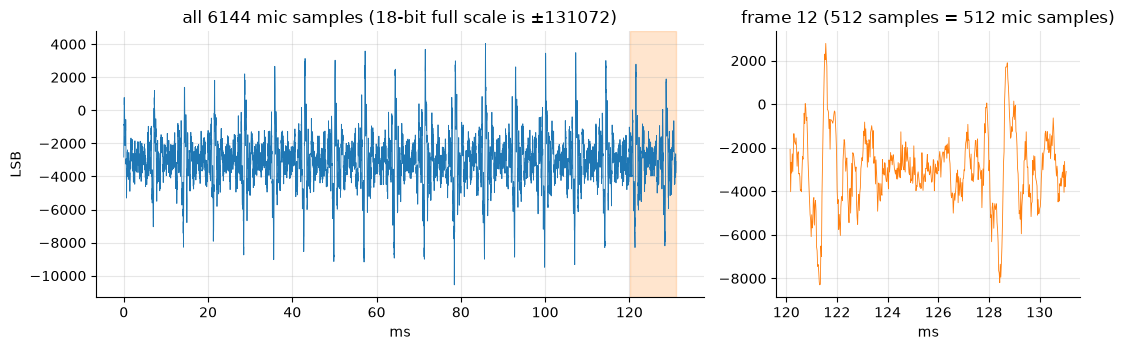

,value
,
rate,46.875 kHz
width,18 bits
peak,10555 LSB
mean (DC),-2997


In [213]:
def load_wav(n):
    from fractions import Fraction
    from scipy.io import wavfile
    from scipy.signal import resample_poly
    rate, w = wavfile.read(WAV_PATH)
    scale = {'i': 2.0 ** (8 * w.dtype.itemsize - 1), 'u': 128.0, 'f': 1.0}[w.dtype.kind]
    w = w.astype(float) - (128 if w.dtype.kind == 'u' else 0)
    w = (w.mean(axis=1) if w.ndim > 1 else w) / scale          # mono, -1 to 1
    ratio = Fraction(MIC_RATE, rate).limit_denominator(1000)
    return np.resize(resample_poly(w, ratio.numerator, ratio.denominator), n)   # loops if too short

def record_mic(n):
    import sounddevice as sd
    r = sd.rec(n, samplerate=MIC_RATE, channels=1, dtype='float32', device=MIC_DEVICE)
    sd.wait()
    return r[:, 0]

def make_signal(n):
    m = np.arange(n)
    t = m / MIC_RATE
    if SOURCE in ('wav', 'mic'):
        audio = load_wav(n) if SOURCE == 'wav' else record_mic(n)
        return quantize(audio * MIC_GAIN * 2 ** (MIC_BITS - 1), MIC_BITS)
    x = np.zeros(n)
    if SOURCE == 'tone':
        x += DC_OFFSET + TONE_AMP * np.sin(2 * np.pi * TONE_HZ * t)
    elif SOURCE == 'chirp':
        x += DC_OFFSET + CHIRP_AMP * np.sin(2 * np.pi * (CHIRP_F0 * t + (CHIRP_F1 - CHIRP_F0) * t ** 2 / (2 * n / MIC_RATE)))
    elif SOURCE == 'speech':
        shape = lambda f: sum(1 / (1 + ((f - F) / 120) ** 2) for F in FORMANTS_HZ)
        buzz = sum(shape(h * PITCH_HZ) * np.sin(2 * np.pi * h * PITCH_HZ * t) for h in range(1, int(7800 / PITCH_HZ)))
        x += DC_OFFSET + SPEECH_AMP * buzz / np.abs(buzz).max() * (0.6 + 0.4 * np.sin(2 * np.pi * 3 * t))
    elif SOURCE == 'click':
        x[(m // SUM_N) == CLICK_AT] = CLICK_LEVEL
    elif SOURCE != 'silence':
        raise ValueError(f"unknown SOURCE {SOURCE!r}")
    if SOURCE in ('tone', 'chirp', 'speech'):
        x += np.random.default_rng(SEED).normal(0, NOISE_LSB, n)
    return quantize(x, MIC_BITS)

x = make_signal(N_MIC)

fig, ax = plt.subplots(1, 2, gridspec_kw={'width_ratios': [2, 1]})
t_ms = np.arange(N_MIC) / MIC_RATE * 1e3
ax[0].plot(t_ms, x, lw=0.6)
lim = ax[0].get_ylim()                       # scale to the data; full-scale lines only show if reached
for s in (1, -1):
    ax[0].axhline(s * 2 ** (MIC_BITS - 1), color='k', ls='--', lw=1)
ax[0].set(title=f'all {N_MIC} mic samples ({MIC_BITS}-bit full scale is ±{2**(MIC_BITS-1)})', xlabel='ms', ylabel='LSB', ylim=lim)
k0 = min(FRAME_TO_PLOT, N_FRAMES) - 1       # same frame the FFT uses
s0 = (FIRST_END - FRAME_N + HOP * k0) * SUM_N
z = slice(s0, s0 + FRAME_N * SUM_N)
ax[0].axvspan(t_ms[z][0], t_ms[z][-1], color='C1', alpha=0.2)
ax[1].plot(t_ms[z], x[z], lw=0.6, color='C1')
ax[1].set(title=f'frame {k0 + 1} ({FRAME_N} samples = {FRAME_N * SUM_N} mic samples)', xlabel='ms')
plt.tight_layout(); plt.show()

peak = max(np.abs(x).max(), 1)
changes([('rate', f'{MIC_RATE/1e3:g} kHz'), ('width', f'{MIC_BITS} bits'),
         ('peak', f'{peak} LSB'), ('mean (DC)', f'{x.mean():.0f}')], cols=('value',))

## 2. Sum of 3
Adds each group of 3 mic samples, so the rate drops by 3:

$$y[n] = x[3n] + x[3n+1] + x[3n+2]$$

That is also a low-pass filter. A sine at frequency $f$ comes out with gain

$$G(f) = \frac{\sin(3\theta)}{\sin\theta}, \qquad \theta = \frac{\pi f}{f_{mic}}$$

which is 3 at DC and 2 (−3.5 dB) at the top frequency $f_s/2$.

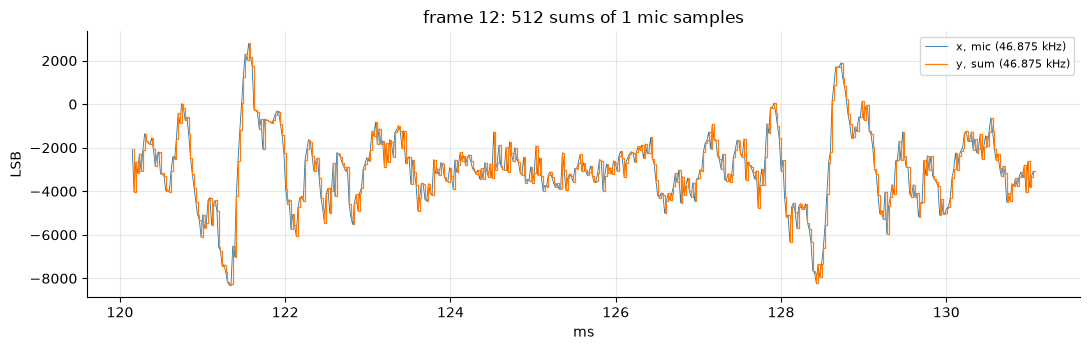

,before,after
,,
rate,46.875 kHz,46.875 kHz
width,18 bits,18 bits
peak,10555,10555
mean (DC),-2997,-2997


In [214]:
y = x[:N_OUT * SUM_N].reshape(N_OUT, SUM_N).sum(axis=1)

k0 = min(FRAME_TO_PLOT, N_FRAMES) - 1       # same frame as the mic plot
n0 = FIRST_END - FRAME_N + HOP * k0          # first output sample of that frame
fr = slice(n0, n0 + FRAME_N)
fm = slice(n0 * SUM_N, (n0 + FRAME_N) * SUM_N)

fig, ax = plt.subplots()
ax.plot(np.arange(N_MIC)[fm] / MIC_RATE * 1e3, x[fm], lw=0.6, label=f'x, mic ({MIC_RATE/1e3:g} kHz)')
ax.step((np.arange(N_OUT)[fr] + 1) * SUM_N / MIC_RATE * 1e3, y[fr], where='pre', lw=0.9, color='C1', label=f'y, sum ({FS/1e3:g} kHz)')
ax.set(title=f'frame {k0 + 1}: {FRAME_N} sums of {SUM_N} mic samples', xlabel='ms', ylabel='LSB'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

changes([
    ('rate', f'{MIC_RATE/1e3:g} kHz', f'{FS/1e3:g} kHz'),
    ('width', f'{MIC_BITS} bits', f'{SUM_BITS} bits'),
    ('peak', f'{np.abs(x).max()}', f'{np.abs(y).max()}'),
    ('mean (DC)', f'{x.mean():.0f}', f'{y.mean():.0f}'),
])


## 3. DC removal
Subtracts a slow running average $\mu$, with weight $a = 2^{-\text{AVERAGE\_SHIFT}}$:

$$\mu[n+1] = \mu[n] + a\,(y[n] - \mu[n]), \qquad d[n] = y[n] - \mu[n]$$

$$p[n] = \mathrm{clip}_{\text{OUT\_BITS}}\big(\mathrm{round}(d[n])\big)$$

As a filter this is a high-pass:

$$H(z) = \frac{1 - z^{-1}}{1 - (1-a)\,z^{-1}}$$

It has a −3 dB cutoff of about $a f_s / 2\pi$. A constant $D$ at the input decays at the output as $D\,(1-a)^n$.

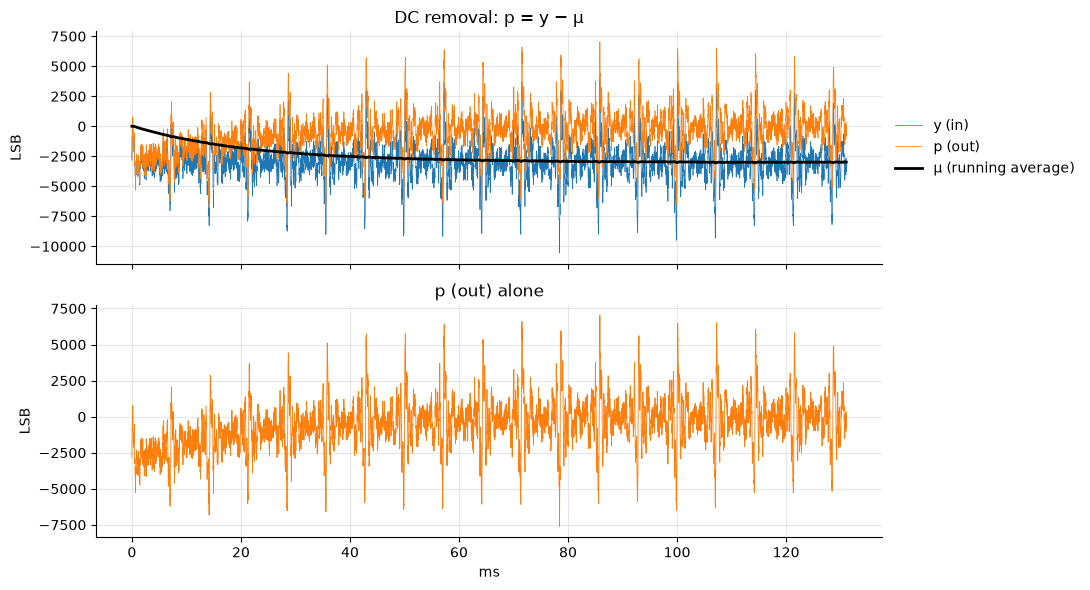

,before,after
,,
width,18 bits,16 bits
peak,10555,7608
"mean, last 512",-2960,31.2
clipped,-,0


In [215]:
mu = np.zeros(N_OUT)
for n in range(N_OUT - 1):
    mu[n + 1] = mu[n] + A * (y[n] - mu[n])
d = y - mu
p = quantize(d, OUT_BITS)
clipped = int(np.sum(np.abs(d) > 2 ** (OUT_BITS - 1) - 1))

t = np.arange(N_OUT) / FS * 1e3
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
ax[0].plot(t, y, lw=0.5, color='C0', label='y (in)')
ax[0].plot(t, p, lw=0.5, color='C1', label='p (out)')
ax[0].plot(t, mu, 'k', lw=2, label='μ (running average)')
ax[0].set(title='DC removal: p = y − μ', ylabel='LSB'); ax[0].legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax[1].plot(t, p, lw=0.6, color='C1')
ax[1].set(title='p (out) alone', xlabel='ms', ylabel='LSB')
plt.tight_layout(); plt.show()

last = slice(-FRAME_N, None)
changes([
    ('width', f'{SUM_BITS} bits', f'{OUT_BITS} bits'),
    ('peak', f'{np.abs(y).max()}', f'{np.abs(p).max()}'),
    (f'mean, last {FRAME_N}', f'{y[last].mean():.0f}', f'{p[last].mean():.1f}'),
    ('clipped', '-', f'{clipped}'),
])


## 4. Frames
Frame $k$ is the latest `FRAME_N` output samples each time `HOP` new ones have arrived (`HOP` = `FS / FRAMES_PER_S`, at most `FRAME_N`), once there are enough for a full frame:

$$\text{frame}_k[i] = p[s_k + i], \quad i = 0 \dots \text{FRAME\_N}-1, \quad s_k = s_1 + \text{HOP}\,(k-1)$$

Neighbouring frames overlap by `FRAME_N − HOP` samples.

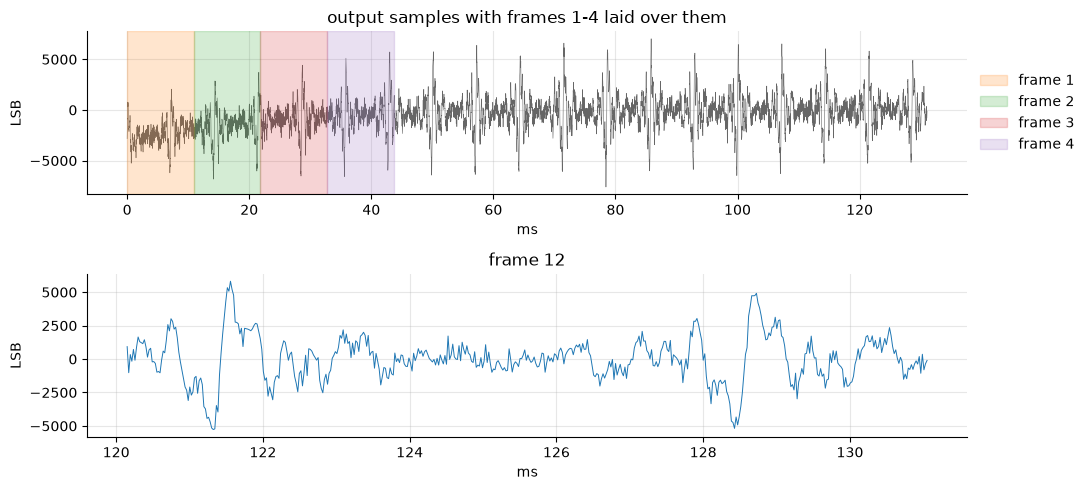

,before,after
,,
unit,1 sample,512 samples
rate,46.875 kHz,91.6 frames/s
overlap,-,0 samples
first frame ready,-,10.9 ms


In [216]:
frame_starts = FIRST_END - FRAME_N + HOP * np.arange(N_FRAMES)
frames = [p[s:s + FRAME_N] for s in frame_starts]
frame_table = pd.DataFrame({'frame': np.arange(1, N_FRAMES + 1), 'first sample': frame_starts,
                            'last sample': frame_starts + FRAME_N - 1,
                            'ready at ms': (frame_starts + FRAME_N) / FS * 1e3}).set_index('frame')

fig, ax = plt.subplots(2, 1, figsize=(11, 5))
ax[0].plot(np.arange(N_OUT) / FS * 1e3, p, lw=0.4, color='0.4')
for k in range(min(4, N_FRAMES)):
    s = frame_starts[k]
    ax[0].axvspan(s / FS * 1e3, (s + FRAME_N) / FS * 1e3, color=f'C{k+1}', alpha=0.2, zorder=3, label=f'frame {k+1}')
ax[0].set(title='output samples with frames 1-4 laid over them', xlabel='ms', ylabel='LSB')
ax[0].legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
kp = min(FRAME_TO_PLOT, N_FRAMES)
ax[1].plot((frame_starts[kp - 1] + np.arange(FRAME_N)) / FS * 1e3, frames[kp - 1], lw=0.7)
ax[1].set(title=f'frame {kp}', xlabel='ms', ylabel='LSB')
plt.tight_layout(); plt.show()
changes([
    ('unit', '1 sample', f'{FRAME_N} samples'),
    ('rate', f'{FS/1e3:g} kHz', f'{FS/HOP:.1f} frames/s'),
    ('overlap', '-', f'{FRAME_N - HOP} samples'),
    ('first frame ready', '-', f'{FIRST_END/FS*1e3:.1f} ms'),
])

## 5. FFT
The discrete Fourier transform of the frame:

$$X[k] = \sum_{i=0}^{N-1} \text{frame}[i]\, e^{-j 2\pi k i / N}$$

Bin $k$ is at $k \cdot f_s / N$, and a sine of amplitude $A$ that lands exactly on a bin gives $|X[k]| = A N / 2$.

The result is then stored in `FFT_OUT_BITS` bits. The whole frame shares one scale $2^{e}$, the smallest that makes the largest part fit, so $X \approx X_q \cdot 2^{e}$.

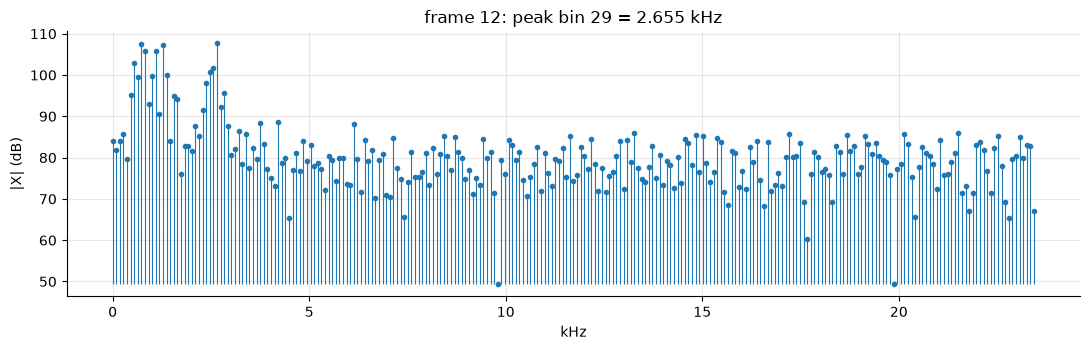

,before,after
,,
width,16 bits,"16+16 bits, scale 2^3"
peak,5816 (time),"944 (bin 29, 2655.0 Hz)"
SQNR,-,81.5 dB


In [217]:
frame = frames[kp - 1].astype(float)
X = np.fft.fft(frame)
top = 2 ** (FFT_OUT_BITS - 1) - 1
biggest = max(np.abs(X.real).max(), np.abs(X.imag).max())
e = max(0, int(np.ceil(np.log2(biggest / top)))) if biggest > 0 else 0
Xq_re, Xq_im = quantize(X.real / 2 ** e, FFT_OUT_BITS), quantize(X.imag / 2 ** e, FFT_OUT_BITS)
Xq = (Xq_re + 1j * Xq_im) * 2.0 ** e
err = Xq - X
sqnr = 10 * np.log10(np.sum(np.abs(X) ** 2) / max(np.sum(np.abs(err) ** 2), 1e-30))
bins = np.arange(FRAME_N // 2 + 1)
amp = 2 * np.abs(X[:FRAME_N // 2 + 1]) / FRAME_N
peak = 1 + int(np.argmax(amp[1:FRAME_N // 2]))

fig, ax = plt.subplots()
mag_db = 20 * np.log10(np.maximum(np.abs(Xq[bins]), 1))
ml, sl, bl = ax.stem(bins * BIN_HZ / 1e3, mag_db, basefmt=' ', bottom=mag_db.min())
plt.setp(sl, linewidth=0.8); plt.setp(ml, markersize=3)
ax.set(title=f'frame {kp}: peak bin {peak} = {peak*BIN_HZ/1e3:.3f} kHz', xlabel='kHz', ylabel='|X| (dB)')
plt.tight_layout(); plt.show()

rows = [
    ('width', f'{OUT_BITS} bits', f'{FFT_OUT_BITS}+{FFT_OUT_BITS} bits, scale 2^{e}'),
    ('peak', f'{np.abs(frame).max():.0f} (time)', f'{amp[peak]:.0f} (bin {peak}, {peak*BIN_HZ:.1f} Hz)'),
]
if SOURCE == 'tone':
    th = np.pi * TONE_HZ / MIC_RATE
    g = np.sin(SUM_N * th) / np.sin(th)      # gain of the sum at the tone
    rows.append(('expected peak', '-', f'{TONE_AMP}·{g:.4f} = {TONE_AMP*g:.0f}'))
rows.append(('SQNR', '-', f'{sqnr:.1f} dB'))
changes(rows)


## 6. Frame to the MCU
For a real input, $X[N-k] = \overline{X[k]}$, so the top half repeats the bottom half and only `SEND_BINS` bins need to be sent. Each bin is re then im, followed by the exponent $e$.

In [218]:
assert np.allclose(X[1:FRAME_N // 2], np.conj(X[:FRAME_N // 2:-1]))
part_bytes = (FFT_OUT_BITS + 7) // 8
frame_bytes = 4 + 2 * part_bytes * SEND_BINS
print(f'X[N-k] = conj(X[k]) ✓   {SEND_BINS} bins x {2*FFT_OUT_BITS} bits + 32-bit header = {frame_bytes} bytes '
      f'= {8*frame_bytes*FS/HOP/1e3:.0f} kbit/s at {FS/HOP:.1f} frames/s')

X[N-k] = conj(X[k]) ✓   256 bins x 32 bits + 32-bit header = 1028 bytes = 753 kbit/s at 91.6 frames/s


## 7. Hamming window and magnitude (MCU)
Multiplying the frame by the Hamming window $w[i] = 0.54 - 0.46\cos(2\pi i/N)$ before the FFT is the same as mixing each bin with its neighbours after it:

$$X_w[k] = 0.54\,X[k] - 0.23\,(X[k-1] + X[k+1])$$

The cell checks that the two match, then finds the magnitude of bins 1 to `SEND_BINS − 2` and the largest.

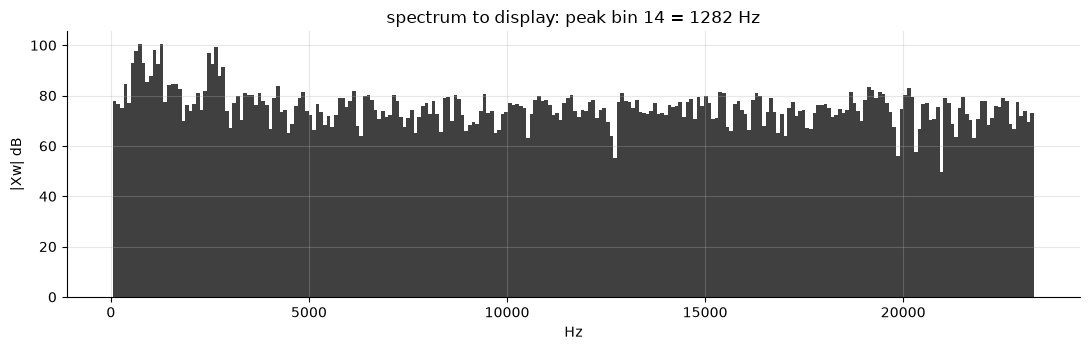

largest difference between window-after and window-before: 2.91e-11 ✓


In [219]:
kk = np.arange(1, SEND_BINS - 1)
Xr = (Xq_re[:SEND_BINS] + 1j * Xq_im[:SEND_BINS]) * 2.0 ** e
Xw = 0.54 * Xr[kk] - 0.23 * (Xr[kk - 1] + Xr[kk + 1])
w = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(FRAME_N) / FRAME_N)
Xw_direct = np.fft.fft(frame * w)[kk]
match = np.max(np.abs(0.54 * X[kk] - 0.23 * (X[kk - 1] + X[kk + 1]) - Xw_direct))
mag = np.abs(Xw)
pk = kk[np.argmax(mag)]

fig, ax = plt.subplots()
ax.bar(kk * BIN_HZ, 20 * np.log10(np.maximum(mag, 1)), width=BIN_HZ, color='0.25')
ax.set(title=f'spectrum to display: peak bin {pk} = {pk*BIN_HZ:.0f} Hz', xlabel='Hz', ylabel='|Xw| dB')
plt.tight_layout(); plt.show()
print(f'largest difference between window-after and window-before: {match:.2e} ✓')

## 8. Summary

In [220]:
display(pd.DataFrame([
    ('microphone', f'{MIC_BITS}', f'{MIC_RATE/1e3:g} kHz', f'peak {np.abs(x).max()} LSB'),
    ('sum of 3', f'{SUM_BITS}', f'{FS/1e3:g} kHz', f'peak {np.abs(y).max()}'),
    ('DC removal', f'{OUT_BITS}', f'{FS/1e3:g} kHz', f'{clipped} clipped'),
    ('frames', f'{FRAME_N} x {OUT_BITS}', f'{FS/HOP:.1f} frames/s', f'{N_FRAMES} frames'),
    ('FFT', f'{FFT_OUT_BITS}+{FFT_OUT_BITS}, scale 2^{e}', f'{FS/HOP:.1f} frames/s', f'SQNR {sqnr:.1f} dB'),
    ('to MCU', '8', f'{frame_bytes} bytes/frame', f'{8*frame_bytes*FS/HOP/1e3:.0f} kbit/s'),
    ('display', '-', '-', f'peak {pk*BIN_HZ:.0f} Hz'),
], columns=['step', 'bits', 'rate', 'result']).set_index('step'))

,bits,rate,result
step,,,
microphone,18,46.875 kHz,peak 10555 LSB
sum of 3,18,46.875 kHz,peak 10555
DC removal,16,46.875 kHz,0 clipped
frames,512 x 16,91.6 frames/s,12 frames
FFT,"16+16, scale 2^3",91.6 frames/s,SQNR 81.5 dB
to MCU,8,1028 bytes/frame,753 kbit/s
display,-,-,peak 1282 Hz


## 9. Live microphone
Runs the same chain on a live stream: each hop of `HOP` output samples is summed, DC-removed, shifted into the frame, then given the FFT, the shared-scale 16-bit storage and the Hamming mix. Only runs when `SOURCE = 'mic'`; press the interrupt button to stop early.

In [221]:
def live(seconds):
    import queue, time
    import sounddevice as sd
    from scipy.signal import lfilter
    q = queue.Queue(maxsize=100)
    block = HOP * SUM_N                                   # mic samples per hop
    def on_audio(indata, n_frames, t_info, status):
        try: q.put_nowait(indata[:, 0].copy())
        except queue.Full: pass                           # drop blocks if the plot falls behind

    zi, ring, got = np.zeros(1), np.zeros(FRAME_N), 0     # filter state, frame buffer, hops received
    kk = np.arange(1, SEND_BINS - 1)
    fig, ax = plt.subplots(2, 1, figsize=(11, 6))
    full = 2 ** (OUT_BITS - 1)
    (l1,) = ax[0].plot(np.arange(FRAME_N) / FS * 1e3, ring, lw=0.7, color='C1')
    ax[0].set(title='latest frame (after DC removal)', xlabel='ms', ylabel='LSB', ylim=(-full, full))
    (l2,) = ax[1].plot(kk * BIN_HZ / 1e3, np.zeros(len(kk)), lw=0.8, color='0.2')
    ax[1].set(title='spectrum', xlabel='kHz', ylabel='|Xw| (dB)', ylim=(0, 20 * np.log10(full * FRAME_N)))
    plt.tight_layout()
    handle = display(fig, display_id=True); plt.close(fig)

    t_end = time.time() + seconds
    try:
        with sd.InputStream(samplerate=MIC_RATE, blocksize=block, channels=1, dtype='float32',
                            device=MIC_DEVICE, callback=on_audio):
            last_draw = 0
            while time.time() < t_end:
                try: blocks = [q.get(timeout=1)]
                except queue.Empty: continue
                while not q.empty(): blocks.append(q.get_nowait())               # catch up on everything waiting
                for raw in blocks:
                    x_b = quantize(raw * MIC_GAIN * 2 ** (MIC_BITS - 1), MIC_BITS)
                    y_b = x_b.reshape(HOP, SUM_N).sum(axis=1)                     # sum of 3
                    d_b, zi = lfilter([1, -1], [1, -(1 - A)], y_b, zi=zi)         # DC removal
                    ring = np.concatenate([ring[HOP:], quantize(d_b, OUT_BITS)])  # frames
                    got += 1
                if got * HOP < FRAME_N or time.time() - last_draw < 0.08:         # fill first; redraw at most ~12x a second
                    continue
                last_draw = time.time()
                Xl = np.fft.fft(ring.astype(float))                               # FFT
                big = max(np.abs(Xl.real).max(), np.abs(Xl.imag).max())
                el = max(0, int(np.ceil(np.log2(big / (2 ** (FFT_OUT_BITS - 1) - 1))))) if big > 0 else 0
                Xr = (quantize(Xl.real / 2 ** el, FFT_OUT_BITS) + 1j * quantize(Xl.imag / 2 ** el, FFT_OUT_BITS)) * 2.0 ** el
                mag = np.abs(0.54 * Xr[kk] - 0.23 * (Xr[kk - 1] + Xr[kk + 1]))    # Hamming + magnitude
                l1.set_ydata(ring); l2.set_ydata(20 * np.log10(np.maximum(mag, 1)))
                ax[1].set_title(f'spectrum: peak {kk[np.argmax(mag)] * BIN_HZ / 1e3:.2f} kHz')
                handle.update(fig)
    except KeyboardInterrupt:
        pass
    print(f'live plot stopped after {got} hops ({got * HOP / FS:.1f} s of audio)')

if SOURCE == 'mic' and LIVE_SECONDS > 0:
    live(LIVE_SECONDS)
else:
    print("Set SOURCE = 'mic' and LIVE_SECONDS > 0 in the Inputs cell to run the live plot.")


Set SOURCE = 'mic' and LIVE_SECONDS > 0 in the Inputs cell to run the live plot.
